In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pandas as pd

STUDENT_ID = 20244080114  # 修改为自己学号
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]

RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")


[Conda 环境] pyexp
[学号] 20244080114
[机器指纹] e49d5bb589bc0a69
[RUN_ID] 20244080114-e49d5bb589bc0a69


### 实验1：NumPy 数组、数据类型与索引

In [2]:
# 1. 创建整数、浮点数、布尔ndarray，输出dtype、shape、ndim
int_arr = np.array([1,2,3,4])
float_arr = np.array([1.1,2.2,3.3])
bool_arr = np.array([True, False, True])

print("整数数组：")
print(f"value:{int_arr}, dtype:{int_arr.dtype}, shape:{int_arr.shape}, ndim:{int_arr.ndim}")
print("浮点数数组：")
print(f"value:{float_arr}, dtype:{float_arr.dtype}, shape:{float_arr.shape}, ndim:{float_arr.ndim}")
print("布尔数组：")
print(f"value:{bool_arr}, dtype:{bool_arr.dtype}, shape:{bool_arr.shape}, ndim:{bool_arr.ndim}")

# 2. np.arange(12)改变形状
a1 = np.arange(12)
a2 = a1.reshape(3,4)
a3 = a1.reshape(2,3,2)
print("\nreshape(3,4):\n",a2)
print("\nreshape(2,3,2):\n",a3)

# 3. (3,4)数组索引：第2行；1‑3列；大于6的元素
print("\n第2行(a2[1])：", a2[1])
print("1至3列(a2[:,1:3])：\n", a2[:,1:3])
print("大于6的元素：", a2[a2>6])

# 4. np.arange(10)布尔索引 | & 
arr10 = np.arange(10)
sel1 = arr10[(arr10 <2) | (arr10>7)]
sel2 = arr10[(arr10>3) & (arr10<7)]
print("\n小于2或大于7：", sel1)
print("大于3且小于7：", sel2)

# 5. (2,2)数组：逐元素乘法 * / multiply；矩阵乘法 @ / matmul
m1 = np.array([[1,2],[3,4]])
m2 = np.array([[5,6],[7,8]])
print("\nm1 * m2 逐元素乘法：\n", m1*m2)
print("np.multiply(m1,m2)：\n", np.multiply(m1,m2))
print("@矩阵乘法：\n", m1 @ m2)
print("np.matmul(m1,m2)：\n", np.matmul(m1,m2))


整数数组：
value:[1 2 3 4], dtype:int64, shape:(4,), ndim:1
浮点数数组：
value:[1.1 2.2 3.3], dtype:float64, shape:(3,), ndim:1
布尔数组：
value:[ True False  True], dtype:bool, shape:(3,), ndim:1

reshape(3,4):
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

reshape(2,3,2):
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

第2行(a2[1])： [4 5 6 7]
1至3列(a2[:,1:3])：
 [[ 1  2]
 [ 5  6]
 [ 9 10]]
大于6的元素： [ 7  8  9 10 11]

小于2或大于7： [0 1 8 9]
大于3且小于7： [4 5 6]

m1 * m2 逐元素乘法：
 [[ 5 12]
 [21 32]]
np.multiply(m1,m2)：
 [[ 5 12]
 [21 32]]
@矩阵乘法：
 [[19 22]
 [43 50]]
np.matmul(m1,m2)：
 [[19 22]
 [43 50]]


### 实验1结果解释
1. numpy数组与Python列表区别：
- ndarray所有元素必须是同一个数据类型；Python列表可以存放不同类型对象。
- ndarray存储连续内存，运算速度快；列表是对象指针，循环运算慢。
- ndarray有shape、ndim属性，支持批量向量化运算。

2. reshape改变形状条件：新shape所有维度乘积 = 数组总元素个数。arange(12)总元素12，3*4=12，2*3*2=12。

3. `*`、`np.multiply()`：逐元素相乘，对应位置元素相乘；
`@`、`np.matmul()`：数学矩阵乘法，行乘列求和。二者运算规则完全不同。


### 实验2：随机抽样、统计与缺失值

In [3]:
np.random.seed(42) #固定随机种子

#1.生成1000个成绩，均值70，标准差10，clip限制0‑100
scores = np.random.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)
print("样本数：", len(scores))
print(f"最小值:{scores.min():.2f},最大值:{scores.max():.2f},均值:{scores.mean():.2f},标准差:{scores.std():.2f},极差:{scores.max()-scores.min():.2f}")

#2.不放回抽样；加权抽样
pop = np.arange(1,11)
sample_no_weight = np.random.choice(pop,size=5,replace=False)
sample_weight = np.random.choice(pop,size=5,replace=False, p=pop/np.sum(pop))
print("\n均匀不放回抽样：", sample_no_weight)
print("按数值大小加权不放回抽样：", sample_weight)

#3.随机排列：不改变原数组；原地打乱
arr_test = np.array([1,2,3,4,5])
arr_shuffle_copy = np.random.permutation(arr_test)
print("\npermutation不修改原数组：")
print("原数组：",arr_test)
print("返回新数组：",arr_shuffle_copy)

arr_test2 = np.array([1,2,3,4,5])
np.random.shuffle(arr_test2)
print("\nshuffle原地打乱：")
print("打乱后原数组：", arr_test2)

#4.设置nan缺失值；普通均值 vs 忽略nan均值
scores_nan = scores.copy()
scores_nan[[9,19,29]] = np.nan #第10、20、30个，索引从0开始，是9,19,29
count_nan = np.sum(np.isnan(scores_nan))
mean_all = np.mean(scores_nan)
mean_no_nan = np.nanmean(scores_nan)
print(f"\n缺失值数量：{count_nan}")
print(f"np.mean直接算(包含nan): {mean_all}")
print(f"np.nanmean忽略缺失值: {mean_no_nan}")

#5.整理成内存表格，给实验4使用，不写磁盘
df_scores = pd.DataFrame({"score":scores_nan, "index":np.arange(len(scores_nan))})


样本数： 1000
最小值:37.59,最大值:100.00,均值:70.18,标准差:9.76,极差:62.41

均匀不放回抽样： [ 4  9  2  6 10]
按数值大小加权不放回抽样： [10  2  8  9  6]

permutation不修改原数组：
原数组： [1 2 3 4 5]
返回新数组： [5 1 3 2 4]

shuffle原地打乱：
打乱后原数组： [1 5 2 4 3]

缺失值数量：3
np.mean直接算(包含nan): nan
np.nanmean忽略缺失值: 70.19620743160239


### 实验2结果说明
1. `np.permutation()`：返回新打乱数组，原始数组保持不变；
`np.random.shuffle()`：直接修改原数组，原地打乱，无返回值。

2. 数组存在`np.nan`时：普通`np.mean()`结果直接变成nan，无法计算；
需要使用`np.nanmean()`自动跳过NaN计算有效值的均值。


### 实验 3：SciPy 数值计算 + Matplotlib 可视化

方程组解 x,y： [2. 3.]
代入验证 A@sol： [9. 8.]

正根求解成功： True 根： [1.41421356] 函数值： [-8.8817842e-16]
负根求解成功： True 根： [-1.41421356] 函数值： [-8.8817842e-16]

极小点x： [-0.50000001] 极小函数值： 1.75

t统计量: -8.55145994324873
p值: 3.292961428703696e-15
p<0.05，拒绝原假设：两组均值存在显著差异


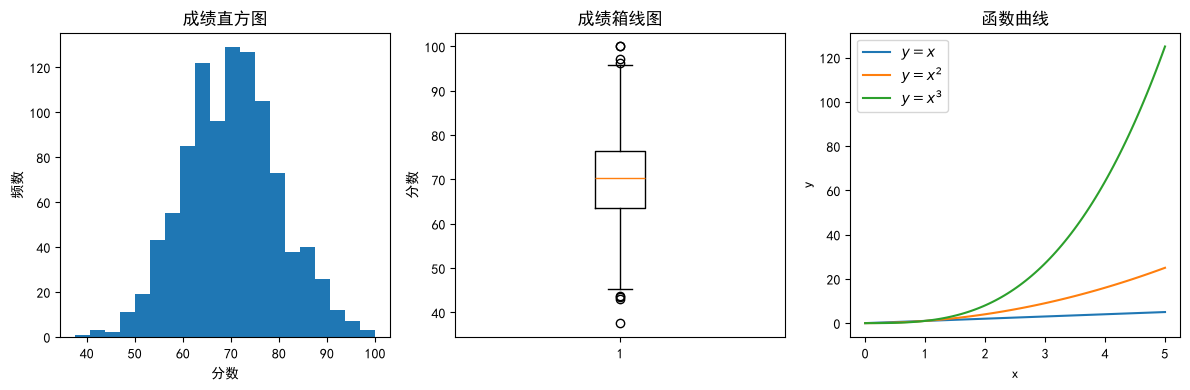

In [4]:
from scipy import linalg
from scipy.optimize import root, minimize
from scipy.stats import ttest_ind

#1.解方程组 3x + y =9 ; x +2y =8
A = np.array([[3,1],[1,2]])
b = np.array([9,8])
sol = linalg.solve(A,b)
print("方程组解 x,y：", sol)
#代入验证
print("代入验证 A@sol：", A @ sol)

#2.求 x^2‑2=0 的正根、负根
def f(x):
    return x**2 -2

res_pos = root(f, x0=1) #初值猜测1，求正根
res_neg = root(f, x0=-1) #初值猜测‑1，求负根
print("\n正根求解成功：", res_pos.success, "根：",res_pos.x, "函数值：",f(res_pos.x))
print("负根求解成功：", res_neg.success, "根：",res_neg.x, "函数值：",f(res_neg.x))

#3.求 f(x)=x²+x+2 最小值
def fun_min(x):
    return x**2 + x + 2
res_min = minimize(fun_min, x0=0)
print("\n极小点x：", res_min.x, "极小函数值：", res_min.fun)
#解析解：导数2x+1=0 → x=-0.5

#4.独立样本t检验
np.random.seed(42)
g1 = np.random.normal(loc=0,scale=1,size=100)
g2 = np.random.normal(loc=1,scale=1,size=100)
t_result = ttest_ind(g1,g2)
print("\nt统计量:",t_result.statistic)
print("p值:",t_result.pvalue)
alpha =0.05
if t_result.pvalue < alpha:
    print(f"p<0.05，拒绝原假设：两组均值存在显著差异")
else:
    print(f"p>=0.05，不能拒绝原假设，无显著差异")

#5.matplotlib绘图
plt.rcParams["font.sans-serif"] = ["SimHei"]
plt.rcParams["axes.unicode_minus"] = False

#实验2成绩直方图
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.hist(scores[~np.isnan(scores_nan)], bins=20)
plt.title("成绩直方图")
plt.xlabel("分数")
plt.ylabel("频数")

#箱线图
plt.subplot(1,3,2)
plt.boxplot(scores[~np.isnan(scores_nan)])
plt.title("成绩箱线图")
plt.ylabel("分数")

# y=x、y=x²、y=x³，0<=x<=5
x = np.linspace(0,5,100)
y1 = x
y2 = x**2
y3 = x**3
plt.subplot(1,3,3)
plt.plot(x,y1,label="$y=x$")
plt.plot(x,y2,label="$y=x^2$")
plt.plot(x,y3,label="$y=x^3$")
plt.legend()
plt.title("函数曲线")
plt.xlabel("x")
plt.ylabel("y")
plt.tight_layout()
plt.show()

观察：y=x^3 增长速度远快于另外两个函数，y 轴范围被拉高到 120，导致 \(y=x\) 的变化幅度在图中占比很小，视觉上近似水平；它本质依然是线性递增的一次函数。

### 实验 4：pandas Series、DataFrame

In [5]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82]
}
df = pd.DataFrame(records)
df = df.set_index("Name") #行索引设置为姓名

#1.新增Total、Average
df["Total"] = df["Math"] + df["English"] + df["Python"]
df["Average"] = df["Total"] / 3
print("行索引：",df.index.tolist())
print("列名：",df.columns.tolist())
print("\n前3行：")
print(df.head(3))
print("\n基本统计：")
print(df.describe())

#2.loc iloc读取Carol；筛选平均分>=80
print("\nloc读取Carol：")
print(df.loc["Carol"])
print("\niloc读取Carol(Carol是第2号索引)：")
print(df.iloc[2])
print("\n平均分>=80学生：")
print(df[df["Average"]>=80])

#3.mean(axis=0)列均值；mean(axis=1)行均值
print("\n各科列均值(axis=0):")
print(df[["Math","English","Python"]].mean(axis=0))
print("\n每个人行均值(axis=1):")
print(df[["Math","English","Python"]].mean(axis=1))

#4.apply求单科最高分；agg；rank
df["max_score"] = df[["Math","English","Python"]].apply(max, axis=1)
print("\n每个人三科最高分：")
print(df["max_score"])
print("\n每科min mean max：")
print(df[["Math","English","Python"]].agg(["min","mean","max"]))
df["Math_rank"] = df["Math"].rank(ascending=False)
print("\n数学成绩排名：")
print(df[["Math","Math_rank"]])

#5.分组groupby + transform
group_info = df.groupby("Group").agg(
    人数=("Group", "count"),
    组平均分=("Average", "mean")
)
print("\n分组统计：")
print(group_info)
df["group_python_mean"] = df.groupby("Group")["Python"].transform("mean")
print("\n增加本组Python平均分列：")
print(df[["Group","Python","group_python_mean"]])


#6.filter保留组内Python平均分>=80的组
df_filter = df.groupby("Group").filter(lambda g: g["Python"].mean() >=80)
print("\nPython组平均分>=80的组学生：")
print(df_filter)

#7.协方差、相关系数矩阵
sub = df[["Math","English","Python"]]
cov_matrix = sub.cov()
corr_matrix = sub.corr()
print("\n协方差矩阵：")
print(cov_matrix)
print("\n皮尔逊相关系数矩阵：")
print(corr_matrix)

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前3行：
      Group  Math  English  Python  Total    Average
Name                                                
Alice     A    88       90      95    273  91.000000
Bob       A    72       68      80    220  73.333333
Carol     B    91       85      89    265  88.333333

基本统计：
            Math    English     Python       Total    Average
count   6.000000   6.000000   6.000000    6.000000   6.000000
mean   79.833333  80.833333  83.666667  244.333333  81.444444
std     9.907909   9.662643   8.547904   25.781130   8.593710
min    65.000000  68.000000  70.000000  208.000000  69.333333
25%    73.750000  74.000000  80.500000  225.750000  75.250000
50%    81.500000  81.000000  84.000000  250.000000  83.333333
75%    87.000000  88.750000  88.250000  263.000000  87.666667
max    91.000000  92.000000  95.000000  273.000000  91.000000

loc读取Carol：
Group              B
Math       

### pandas结果解释
1. `loc`：按标签索引（名字Name）；`iloc`：按数字位置索引。
2. `axis=0`：沿着行方向运算，求每一列统计；`axis=1`沿着列方向运算，求每一行统计。
3. transform：分组计算后，把分组结果广播到每一行，保持原DataFrame行数不变。
4. 协方差：符号代表两个变量变化同向/反向；相关系数范围[-1,1]，绝对值越接近1线性相关性越强。
